## Final Fleet Planning/Routing base case
### 11 cities, 5 aicraft types

In [1]:
using CSV, DataFrames, JuMP, Gurobi, Plots, Random
using LaTeXStrings, StatsPlots, LinearAlgebra, Geodesics

In [2]:
city_coords = CSV.read("data-finalbase/realcities.csv", DataFrame);
aircraft_costs = CSV.read("data-finalbase/cost_BTS.csv", DataFrame);
aircraft_ranges = CSV.read("data-finalbase/range.csv", DataFrame);
aircraft_speeds = CSV.read("data-finalbase/cruise_speed.csv", DataFrame);

In [3]:
function distance_matrix(C::Matrix)
    n = size(C,1)
    D = zeros((n,n))
    
    a, f = Geodesics.EARTH_R_MAJOR_WGS84, Geodesics.F_WGS84
    # Unit conversion factor: 1 nmi = 1852 meters
    conv_fac = 1/1852
    for i in 1:n
        for j in 1:n
            loni, lati = C[i,2], C[i,1]
            lonj, latj = C[j,2], C[j,1]
            dist, _ , _ = Geodesics.inverse(deg2rad.((loni, lati, lonj, latj))..., a, f)
            dist_nmi = dist * conv_fac
            D[i,j] = dist_nmi
        end
    end
    return D
end

distance_matrix (generic function with 1 method)

In [4]:
C = Matrix(city_coords);
O = Vector(aircraft_costs[:,2]);
R = Vector(aircraft_ranges[:,2]);
S = Vector(aircraft_speeds[:,2]);
D = distance_matrix(C);

In [5]:
V = 1:size(C,1);
n = size(C,1);
m = 5;

In [6]:
model = Model(Gurobi.Optimizer);

@variable(model, X[i in V, j in V, k in 1:m], Bin);
@variable(model, Y[i in V, k in 1:m], Bin);
@variable(model, 2 <= U[i in V, k in 1:m] <= length(V));

Set parameter Username
Academic license - for non-commercial use only - expires 2024-09-07


In [7]:
fix.(U[1,:], 1; force = true);

In [8]:
@objective(
    model,
    Min,
    sum(O[k] * (D[i,j]/S[k]) * X[i,j,k] for i in V, j in V, k in 1:m),
);

In [9]:
@constraints(model, begin
    # For all nodes and routes, flow out == flow in
    [i in V, k in 1:m], sum(X[i,:,k]) == sum(X[:,i,k])
    # Flow in and out of other nodes is 1
    [i in V; i != 1], sum(X[i,:,:]) == 1
    [i in V; i != 1], sum(X[:,i,:]) == 1
    # MTZ constraints
    [i in V, j in V, k in 1:m; i != 1 && j != 1],
        U[i,k] - U[j,k] + 1 <= (n - 1) * (1 - X[i,j,k])
    # y[i, k] is 1 if node i is in route k
    [i in V, k in 1:m], sum(X[i,:,k]) == Y[i,k]
    # each node can be in at most one route, except node 1, which is in every 
    # route
    [i in V; i != 1], sum(Y[i,:]) <= 1
    # Range constraint
    [i in V, j in V, k in 1:m], D[i,j] * X[i,j,k] <= R[k]
end);

In [10]:
optimize!(model)
for k in 1:m
    print("Route $k: 1")
    i = 1
    while true
        for j in V
            if value(X[i, j, k]) > 0.5
                print(" => $j")
                i = j
                break
            end
        end
        if i == 1
            println()
            break
        end
    end
end

Gurobi Optimizer version 10.0.2 build v10.0.2rc0 (win64)

CPU model: 12th Gen Intel(R) Core(TM) i7-1255U, instruction set [SSE2|AVX|AVX2]
Thread count: 10 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 1245 rows, 715 columns and 4860 nonzeros
Model fingerprint: 0x665b1699
Variable types: 55 continuous, 660 integer (660 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+03]
  Objective range  [7e+02, 4e+04]
  Bounds range     [1e+00, 1e+01]
  RHS range        [1e+00, 3e+03]
Presolve removed 879 rows and 301 columns
Presolve time: 0.01s
Presolved: 366 rows, 414 columns, 4075 nonzeros
Variable types: 50 continuous, 364 integer (364 binary)

Root relaxation: objective 2.462289e+04, 32 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

     0     0 24622.8890    0   19          - 24622.8890      -    

In [11]:
Xopt = Array(value.(X[:,:,:]));

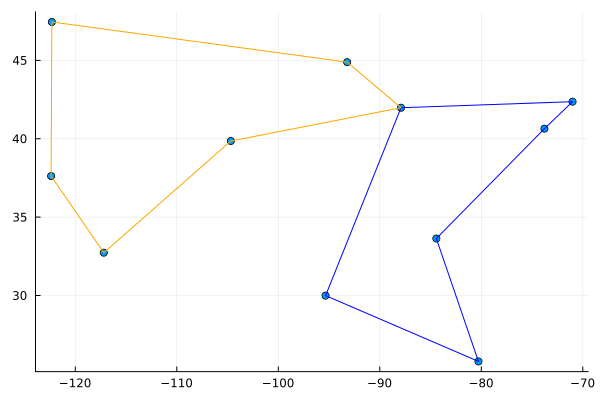

In [12]:
fig = scatter(C[:,2], C[:,1], legend=false);
for k in 1:m
    for i in V
        for j in V
            if (Xopt[i,j,k] > 0.95) 
                xcoords = [C[i,2];C[j,2]];
                ycoords = [C[i,1];C[j,1]];
 
                if (k == 1)
                    plot!(fig, xcoords, ycoords, color=:red);
                elseif (k == 2)
                    plot!(fig, xcoords, ycoords, color=:blue);
                elseif (k == 3)
                    plot!(fig, xcoords, ycoords, color=:green);
                elseif (k == 4)
                    plot!(fig, xcoords, ycoords, color=:orange);
                elseif (k == 5)
                    plot!(fig, xcoords, ycoords, color=:cyan);
                end
            end
        end
    end
end
fig